In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE

from sklearn.metrics import accuracy_score
import xgboost as xgb
from xgboost import XGBClassifier
import joblib
from sklearn.metrics import mean_squared_error

In [3]:
df_train_data_clean = pd.read_csv("train_data_clean_full.csv")
df_train_data_clean = df_train_data_clean.drop(columns = ["Unnamed: 0", "case_id", "patientid"])
df_train_data_clean

,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay,Numero_registros_paciente
0,8,c,3,Z,3,radiotherapy,R,F,2.0,7.0,Emergency,Extreme,2,51-70,4911.0,Hasta 10 dias,14
1,2,c,5,Z,2,radiotherapy,S,F,2.0,7.0,Trauma,Extreme,2,51-70,5954.0,Más de 40 días,14
2,10,e,1,X,2,anesthesia,S,E,2.0,7.0,Trauma,Extreme,2,51-70,4745.0,Menos de 40 dias,14
3,26,b,2,Y,2,radiotherapy,R,D,2.0,7.0,Trauma,Extreme,2,51-70,7272.0,Más de 40 días,14
4,26,b,2,Y,2,radiotherapy,S,D,2.0,7.0,Trauma,Extreme,2,51-70,5558.0,Más de 40 días,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318320,6,a,6,X,3,radiotherapy,Q,F,4.0,23.0,Emergency,Moderate,3,21-50,4144.0,Menos de 40 dias,1
318321,24,a,1,X,2,anesthesia,Q,E,4.0,8.0,Urgent,Moderate,4,71-100,6699.0,Menos de 40 dias,1
318322,7,a,4,X,3,gynecology,R,F,4.0,10.0,Emergency,Minor,3,71-100,4235.0,Menos de 40 dias,1
318323,11,b,2,Y,3,anesthesia,Q,D,3.0,8.0,Trauma,Minor,5,0-20,3761.0,Menos de 40 dias,1


In [124]:
df_train_data_clean.groupby("Stay").size()

Stay
Hasta 10 dias        23602
Menos de 40 dias    220711
Más de 40 días       74012
dtype: int64

In [125]:
# Pasamos columna "Stay" a valor numérico:
df_train_data_clean["Stay"] = df_train_data_clean["Stay"].replace({
    "Hasta 10 dias": 0,
    "Menos de 40 dias": 1,
    "Más de 40 días": 2
})

C:\Users\jtroyano.ARQG-520\AppData\Local\Temp\ipykernel_12508\952093151.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_train_data_clean["Stay"] = df_train_data_clean["Stay"].replace({


## SEPARAMOS TRAIN Y TEST

In [126]:
X = df_train_data_clean.drop(columns = "Stay")
y = df_train_data_clean["Stay"]

In [127]:
# Pdemos separar directamente en 4 tablas con el nombre propio de cada cual:
X_train, X_test, y_train, y_test,  = train_test_split(
    X, y,
    train_size = 0.75, # Separará el 75% de los datos para training, Selección aleatoria
    test_size = 0.25,   # Separará el 25% de los datos para testeo, Selección aleatoria
    random_state = 10
)

## GENERAMOS DUMMIES

In [128]:
X_train.columns

Index(['Hospital_code', 'Hospital_type_code', 'City_Code_Hospital',
       'Hospital_region_code', 'Available Extra Rooms in Hospital',
       'Department', 'Ward_Type', 'Ward_Facility_Code', 'Bed Grade',
       'City_Code_Patient', 'Type of Admission', 'Severity of Illness',
       'Visitors with Patient', 'Age', 'Admission_Deposit',
       'Numero_registros_paciente'],
      dtype='object')

In [129]:
X_train = pd.get_dummies(
    X_train,
    columns= [
        "Hospital_code",
        "Hospital_type_code",
        "City_Code_Hospital",
        "Hospital_region_code",
        "Department",
        "Ward_Type",
        'Ward_Facility_Code',
        "Bed Grade",
        "City_Code_Patient",
        "Type of Admission",
        "Severity of Illness",
        "Age",
    ],
    drop_first = True  # Me elimina una columna porque siempre sobra en el modelo. No es necesaria
)

X_test = pd.get_dummies(
    X_test,
    columns= [
        "Hospital_code",
        "Hospital_type_code",
        "City_Code_Hospital",
        "Hospital_region_code",
        "Department",
        "Ward_Type",
        'Ward_Facility_Code',
        "Bed Grade",
        "City_Code_Patient",
        "Type of Admission",
        "Severity of Illness",
        "Age",        
    ],
    drop_first = True  # Me elimina una columna porque siempre sobra en el modelo. No es necesaria
)

In [130]:
# Nos aseguramos que no haya puesto más columnas en una tabla que en otra porque hubieran más categorías en alguna columna:
X_train.columns.size

114

In [131]:
X_test.columns.size

114

In [132]:
# Si queremos verlo en 0 y 1:
X_train = X_train * 1
X_test = X_test * 1

In [133]:
X_test

,Available Extra Rooms in Hospital,Visitors with Patient,Admission_Deposit,Numero_registros_paciente,Hospital_code_2,Hospital_code_3,Hospital_code_4,Hospital_code_5,Hospital_code_6,Hospital_code_7,...,City_Code_Patient_8.0,City_Code_Patient_9.0,City_Code_Patient_other,Type of Admission_Trauma,Type of Admission_Urgent,Severity of Illness_Minor,Severity of Illness_Moderate,Age_21-50,Age_51-70,Age_71-100
67827,2,4,5193.0,5,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
292257,4,2,4464.0,2,0,1,0,0,0,0,...,0,0,0,0,1,0,1,1,0,0
196656,2,2,4246.0,8,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
243694,2,3,6027.0,3,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
129280,3,2,4635.0,4,0,0,0,0,0,0,...,0,0,0,0,1,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25999,2,4,6752.0,4,0,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0
45855,4,3,4247.0,1,0,0,0,0,0,0,...,1,0,0,0,0,1,0,1,0,0
181883,3,4,4792.0,3,0,0,0,0,1,0,...,0,0,0,1,0,1,0,1,0,0
309533,3,2,4908.0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0


## GENERACIÓN DEL MODELO - RESTRINGIDO

In [134]:
for i in range(1,20):
    modelo = XGBClassifier(max_depth = i)
    modelo.fit(X_train, y_train)    
    
    y_pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    print(i, "->", np.round(acc,3))

1 -> 0.755
2 -> 0.762
3 -> 0.773
4 -> 0.776
5 -> 0.777
6 -> 0.778
7 -> 0.778
8 -> 0.778
9 -> 0.778
10 -> 0.776
11 -> 0.775
12 -> 0.773
13 -> 0.771
14 -> 0.769
15 -> 0.768
16 -> 0.767
17 -> 0.767
18 -> 0.766
19 -> 0.765


In [135]:
# Comprobación del "Depth" seleccionado
modelo = XGBClassifier(max_depth = 10)
modelo.fit(X_train, y_train)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [136]:
y_pred = modelo.predict(X_test)
accuracy_score(y_test, y_pred)

0.7762936342388982

In [137]:
y_pred

array([1, 1, 1, ..., 1, 1, 1], shape=(79582,))

In [138]:
# Evaluación
print("RMSE:", mean_squared_error(y_test, y_pred))

RMSE: 0.22958709255861878


In [139]:
# Cálculo de auc
from sklearn.metrics import roc_auc_score

proba = modelo.predict_proba(X_test)  # shape = (n_samples, 3)

auc_ovr_macro = roc_auc_score(y_test, proba, multi_class="ovr", average="macro")
auc_ovr_weighted = roc_auc_score(y_test, proba, multi_class="ovr", average="weighted")

print("AUC OvR macro:", auc_ovr_macro)
print("AUC OvR weighted:", auc_ovr_weighted)

AUC OvR macro: 0.822055079261697
AUC OvR weighted: 0.8037672084856089


In [140]:
import pickle

with open("modelo_hospital.pkl", "wb") as f:
    pickle.dump(modelo, f)

In [141]:
X_train

,Available Extra Rooms in Hospital,Visitors with Patient,Admission_Deposit,Numero_registros_paciente,Hospital_code_2,Hospital_code_3,Hospital_code_4,Hospital_code_5,Hospital_code_6,Hospital_code_7,...,City_Code_Patient_8.0,City_Code_Patient_9.0,City_Code_Patient_other,Type of Admission_Trauma,Type of Admission_Urgent,Severity of Illness_Minor,Severity of Illness_Moderate,Age_21-50,Age_51-70,Age_71-100
296032,5,2,3718.0,3,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
39843,2,2,6151.0,9,0,0,0,0,0,0,...,0,0,0,1,0,0,1,1,0,0
164783,3,2,5868.0,5,0,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0
308326,4,2,4177.0,1,0,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0
19614,2,2,5918.0,4,0,0,0,0,0,0,...,1,0,0,1,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299741,4,7,6517.0,2,0,1,0,0,0,0,...,1,0,0,1,0,0,0,1,0,0
9372,2,4,4546.0,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
105595,4,4,4199.0,7,0,0,0,1,0,0,...,1,0,0,1,0,1,0,0,1,0
93553,4,2,6178.0,9,0,0,0,0,0,0,...,0,0,0,1,0,0,1,1,0,0


# ESTUDIO DE IMPORTANCIA DE LAS VARIABLES

In [142]:
from xgboost import plot_importance
import itertools
import pickle

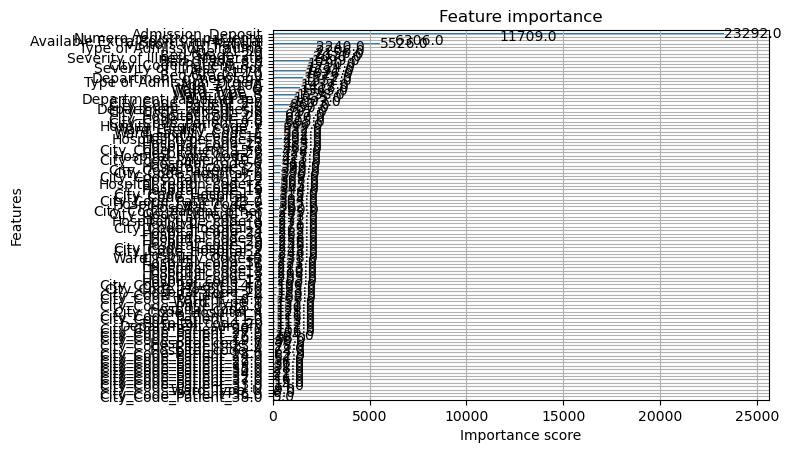

In [143]:
plot_importance(modelo)
plt.show()

In [144]:
# VAMOS A ESTUDIAR QUÉ VARIABLES PUEDEN CAMBIAR LA PREDICCIÓN
# Cargar modelo
modelo = pickle.load(open("modelo_hospital.pkl", "rb"))

# --- Variables que queremos probar ---
valores = {
    "Severity_of_Illness":["Minor","Moderate","Extreme"],
    "Type_of_Admission":["Emergency","Trauma","Urgent"],
    "Bed_Grade":[1,2,3,4],
    "Ward_Type":["P","Q","R","S","T","U"]
}

# Generar todas las combinaciones posibles
combinaciones = list(itertools.product(*valores.values()))

# Lista para guardar resultados
resultados = []

for combo in combinaciones:
    df = pd.DataFrame([combo], columns=valores.keys())

    # Convertir a dummies
    df_dummies = pd.get_dummies(df)

    # Asegurarse de que estén todas las columnas que el modelo espera
    modelo_columns = modelo.get_booster().feature_names
    for col in modelo_columns:
        if col not in df_dummies.columns:
            df_dummies[col] = 0
    df_dummies = df_dummies[modelo_columns]

    # Predicción
    pred = modelo.predict(df_dummies)

    # Guardar solo si predicción es 1 o 2
    if pred[0] in [1, 2]:
        resultados.append((combo, pred[0]))

# Mostrar resultados
print(f"Se encontraron {len(resultados)} combinaciones que dan 1 o 2:")
for r in resultados:
    print(r)

C:\Users\jtroyano.ARQG-520\AppData\Local\Temp\ipykernel_12508\525777459.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_dummies[col] = 0
C:\Users\jtroyano.ARQG-520\AppData\Local\Temp\ipykernel_12508\525777459.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_dummies[col] = 0
C:\Users\jtroyano.ARQG-520\AppData\Local\Temp\ipykernel_12508\525777459.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining a

Se encontraron 216 combinaciones que dan 1 o 2:
(('Minor', 'Emergency', 1, 'P'), np.int64(1))
(('Minor', 'Emergency', 1, 'Q'), np.int64(1))
(('Minor', 'Emergency', 1, 'R'), np.int64(1))
(('Minor', 'Emergency', 1, 'S'), np.int64(1))
(('Minor', 'Emergency', 1, 'T'), np.int64(1))
(('Minor', 'Emergency', 1, 'U'), np.int64(1))
(('Minor', 'Emergency', 2, 'P'), np.int64(1))
(('Minor', 'Emergency', 2, 'Q'), np.int64(1))
(('Minor', 'Emergency', 2, 'R'), np.int64(1))
(('Minor', 'Emergency', 2, 'S'), np.int64(1))
(('Minor', 'Emergency', 2, 'T'), np.int64(1))
(('Minor', 'Emergency', 2, 'U'), np.int64(1))
(('Minor', 'Emergency', 3, 'P'), np.int64(1))
(('Minor', 'Emergency', 3, 'Q'), np.int64(1))
(('Minor', 'Emergency', 3, 'R'), np.int64(1))
(('Minor', 'Emergency', 3, 'S'), np.int64(1))
(('Minor', 'Emergency', 3, 'T'), np.int64(1))
(('Minor', 'Emergency', 3, 'U'), np.int64(1))
(('Minor', 'Emergency', 4, 'P'), np.int64(1))
(('Minor', 'Emergency', 4, 'Q'), np.int64(1))
(('Minor', 'Emergency', 4, 'R'),

C:\Users\jtroyano.ARQG-520\AppData\Local\Temp\ipykernel_12508\525777459.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_dummies[col] = 0
C:\Users\jtroyano.ARQG-520\AppData\Local\Temp\ipykernel_12508\525777459.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_dummies[col] = 0
C:\Users\jtroyano.ARQG-520\AppData\Local\Temp\ipykernel_12508\525777459.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining a